<div style="background:linear-gradient(135deg,#1f4e79,#2f80ed 55%,#56ccf2);color:white;padding:26px 30px;border-radius:14px;margin:6px 0">
    <div style="font-size:2em;font-weight:800">
        Simple Statistics
    </div>
    <div style="font-size:1.1em;opacity:.95;margin-top:6px">
        Means, medians and counts of real hourly PM2.5 data
    </div>
</div>

<div style="border-left:7px solid #f2994a;background:rgba(242,153,74,.15);padding:10px 18px;margin:10px 0;border-radius:8px;line-height:1.5">
    <div style="font-weight:700;font-size:1.08em;margin-bottom:4px">
        ✍️ How to use this notebook...
    </div>
    <ul>
        <li>
            <b>Shift + Enter</b> runs a cell. <b>Do not use “Run All.”</b> Run the two setup cells first, then work down the page in order.
        </li>
        <li>
            Read each passage, then run the code under it and look at what comes out.
        </li>
        <li>
            Change a value and run the cell again. When a cell fails, read the red message from the bottom up.
        </li>
    </ul>
</div>

<div style="border-left:7px solid #2f80ed;background:rgba(47,128,237,.12);padding:10px 18px;margin:10px 0;border-radius:8px;line-height:1.5">
    <div style="font-weight:700;font-size:1.08em;margin-bottom:4px">
        🎯 Outline of this Course Module
    </div>
    <ul>
        <li>
            <b> Section 1: The Python Standard Library </b>
        </li>
        <li>
            <b> Section 2: NumPy </b>
        </li>
        <li>
            <b> Section 3: Pandas </b>
        </li>
        <li>
            <b> Section 4: Simple Plots </b>
        </li>
    </ul>
</div>

In [1]:
# Cell 1
# Setup, part 1: bring in the tools this notebook uses.


# The Python Standard Library 
import math
import statistics

# Useful packages
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
# Cell 2
# Loading in some Sample Dataset I stored for the course
from marama_2026 import sample_datasets as sd

df = sd.load_aqs_pm25() # This returns a pandas DataFrame type. We'll get into that later...

<div style="border-left:7px solid #2f80ed;background:rgba(47,128,237,.12);padding:10px 18px;margin:10px 0;border-radius:8px;line-height:1.5">
    What is in <code>df</code>, the table the last cell loaded? One row for each hour at each of eight monitors in Allegheny County, Pennsylvania, for 2025, which makes 60,264 rows. The column we use is <code>Sample Value</code>, the PM2.5 reading for that hour in micrograms per cubic meter, and <code>Site ID</code> says which monitor made it. Some readings are blank, because the monitor produced no value for that hour, and that turns out to matter in the next few cells.
</div>

<div style="background:linear-gradient(90deg,#2f80ed,#56ccf2);color:white;padding:10px 20px;border-radius:10px;margin:22px 0 6px 0">
    <span style="font-size:1.3em;font-weight:800">
        Section 1
    </span>
    <span style="font-size:1.2em;font-weight:600"> &nbsp;
        The Python Standard Library
    </span>
    <div style="opacity:.92">
        Simple stats with nothing installed: math and statistics
    </div>
</div>

In [ ]:
# Cell 3
pm25 = df['Sample Value']
print(type(pm25)) # Should return <class 'pandas.Series'>
pm25 = pm25.to_list() # I doing some magic to conver the output into a list...
print(type(pm25)) # Should return <class 'list'>

<class 'pandas.Series'>
<class 'list'>


<div style="border-left:7px solid #9aa5b1;background:rgba(154,165,177,.15);padding:8px 16px;margin:10px 0;border-radius:8px;line-height:1.5;font-size:.95em">
    <div style="font-weight:700;margin-bottom:4px">
        📎 Footnote: type()
    </div>
    The call <code>type(x)</code> asks Python what kind of value <code>x</code> is, and the answer prints as <code>&lt;class ...&gt;</code>. A <code>pandas.Series</code> is pandas' name for one column of a table. A <code>list</code> is the plain Python collection from Python Basics. When you are unsure what a function has handed you, <code>type()</code> is the quickest way to find out.
</div>

In [4]:
# Cell 4

# What is the maximum value in the list?
print("Max:", max(pm25))

# What is the minimum value in the list?
print("Min:", min(pm25))

# What is the mean value in the list? 
print("Mean:", statistics.mean(pm25))


Max: 114.9
Min: 0.3
Mean: nan


<div style="border-left:7px solid #2f80ed;background:rgba(47,128,237,.12);padding:10px 18px;margin:10px 0;border-radius:8px;line-height:1.5">
    Why did that print <code>nan</code>? Somewhere in the 60,264 readings there are hours with no value, and a sum that includes an unknown is unknown. You might reach for <code>statistics.nanmean</code>, but the module has no such function. The call stops with an <code>AttributeError</code>, because nothing in <code>statistics</code> knows how to skip a missing value.
    <p>
        So I filter first. The list comprehension in the next cell keeps each <code>x</code> for which <code>math.isnan(x)</code> is False, and the functions after it run on the cleaned list.
    </p>
</div>

In [5]:
# Cell 5
pm25_list_clean = [x for x in pm25 if not math.isnan(x)]

In [33]:
# Cell 6

# What is the mean value of the list, excluding the NaNs? 
print("Mean:", statistics.mean(pm25_list_clean))

# What is the median value of the list, excluding the NaNs?
print("Median:", statistics.median(pm25_list_clean))
# What is the standard deviation of the list, excluding the NaNs?
print("Standard Deviation:", statistics.stdev(pm25_list_clean))

Mean: 8.192677146957712
Median: 6.4
Standard Deviation: 6.251897229415633


<div style="border-left:7px solid #2f80ed;background:rgba(47,128,237,.12);padding:10px 18px;margin:10px 0;border-radius:8px;line-height:1.5">
    What do those three numbers say about a typical hour? The <b>mean</b>, 8.19, is every reading added up and divided by how many there are. The <b>median</b>, 6.4, is the middle reading: line up all 59,922 in order and half of them are lower. The mean sits higher because a few very high hours, up to 114.9, drag it up and cannot move the median. The <b>standard deviation</b>, 6.25, is roughly how far a reading sits from the mean, so it measures how spread out the hours are.
</div>

<div style="background:linear-gradient(90deg,#2f80ed,#56ccf2);color:white;padding:10px 20px;border-radius:10px;margin:22px 0 6px 0">
    <span style="font-size:1.3em;font-weight:800">Section 2</span><span style="font-size:1.2em;font-weight:600"> &nbsp;NumPy</span>
    <div style="opacity:.92">
        Arrays, percentiles, missing values and counting
    </div>
</div>

<div style="border-left:7px solid #2f80ed;background:rgba(47,128,237,.12);padding:10px 18px;margin:10px 0;border-radius:8px;line-height:1.5">
    <div style="font-weight:700;font-size:1.08em;margin-bottom:4px">
        🔢 NumPy is the package Python uses for fast arithmetic on whole collections of numbers.
    </div>
    Its name is short for Numerical Python. It gives Python one new kind of value, the <b>array</b>, and a large set of functions that work on arrays.
    <ul style="margin:6px 0">
        <li style="margin-bottom:4px">
            <b>Array:</b> 
            An ordered block of values that all share one type, so a million PM2.5 readings take up far less room than a list of a million separate Python numbers.
        </li>
        <li style="margin-bottom:4px">
            <b>Whole-array operations:</b> 
            <code>a * 2</code> or <code>a &gt; 35</code> acts on every element at once, with no loop to write.
        </li>
        <li style="margin-bottom:4px">
            <b>Statistics included:</b> 
            <code>mean</code>, <code>median</code>, <code>std</code> and <code>percentile</code> are built in, plus <code>nan</code> versions such as <code>nanmean</code> that skip missing values.
        </li>
        <li style="margin-bottom:4px">
            <b>The foundation:</b> 
            pandas, SciPy, Matplotlib and xarray are all built on NumPy arrays, so what you learn here carries over to every other package in this course.
        </li>
        <li style="margin-bottom:4px">
            <b>Not in the standard library:</b> It is installed separately, and by convention imported as <code>import numpy as np</code>.
        </li>
        <li style="margin-bottom:4px">
            <b>Fast:</b> The core of NumPy is written in C, and its linear algebra calls the compiled BLAS and LAPACK libraries that grew out of Fortran. A loop over a million readings runs in that compiled code instead of line by line in Python, which is why NumPy is the usual choice for anything beyond a few thousand values.
        </li>
    </ul>
    <div style="font-weight:300;font-size:1.08em;margin-bottom:4px">
        Indexing works as you already know it: zero-based, with slices. What is new is that you can also index with a mask of <code>True</code> and <code>False</code>, which is how we will pick out the hours above a limit.
    </div>
</div>


In [40]:
# Cell 7
pm25_array = np.array(pm25)
print("pm25 is a", type(pm25).__name__, "with", len(pm25), "values")
print("pm25_array is an", type(pm25_array).__name__, "with", pm25_array.size, "values, stored as", pm25_array.dtype)

pm25 is a list with 60264 values
pm25_array is an ndarray with 60264 values, stored as float64


<div style="border-left:7px solid #9aa5b1;background:rgba(154,165,177,.15);padding:8px 16px;margin:10px 0;border-radius:8px;line-height:1.5;font-size:.95em">
    <div style="font-weight:700;margin-bottom:4px">
        📎 Footnote: the three new pieces in the cell above
    </div>
    <ul style="margin:6px 0">
        <li style="margin-bottom:4px"><b><code>.__name__</code></b>: every type carries its own name as text. <code>type(pm25)</code> is the type itself, and <code>type(pm25).__name__</code> is just the word <code>list</code>. The double underscores mark a name Python defines for itself.</li>
        <li style="margin-bottom:4px"><b><code>.size</code></b>: the total number of values in an array. For a plain row of readings it matches <code>len()</code>, but for a table of rows and columns, <code>.size</code> counts every value and <code>len()</code> counts only the rows.</li>
        <li style="margin-bottom:4px"><b><code>.dtype</code></b>: the type of the values inside the array. <code>float64</code> means decimal numbers, each stored in 64 bits (8 bytes). Every value in an array shares one dtype, which is part of why NumPy is fast.</li>
    </ul>
    None of the three has parentheses after it. They are <b>attributes</b>, facts the object already holds, not actions it performs like <code>.mean()</code>.
</div>

<div style="border-left:7px solid #9aa5b1;background:rgba(154,165,177,.15);padding:8px 16px;margin:10px 0;border-radius:8px;line-height:1.5;font-size:.95em">
    <div style="font-weight:700;margin-bottom:4px">
        📎 Footnote: this cell runs, but the answers are not numbers
    </div>
    Python raises no error here. All four lines print <code>nan</code>, short for "not a number". 342 of the 60,264 readings are blank, and a blank in an array is stored as <code>nan</code>. Any arithmetic that touches a <code>nan</code> returns <code>nan</code>, so one blank hour is enough to spoil a mean, a median or a standard deviation. Run the cell, read the output, and then keep going: the next few cells show how to find the blanks and how to work around them.
</div>

In [10]:
# Cell 8
print("Numpy Stats")
print("Mean:", pm25_array.mean())
print("Median:", np.median(pm25_array))
print("Standard Deviation (n):", pm25_array.std())
print("Standard Deviation (n-1):", pm25_array.std(ddof=1))

Numpy Stats
Mean: nan
Median: nan
Standard Deviation (n): nan
Standard Deviation (n-1): nan


In [11]:
# Cell 9
np.isnan(pm25_array).sum()

np.int64(342)

<div style="border-left:7px solid #9aa5b1;background:rgba(154,165,177,.15);padding:8px 16px;margin:10px 0;border-radius:8px;line-height:1.5;font-size:.95em">
    <div style="font-weight:700;margin-bottom:4px">
        📎 Footnote: why not <code>== np.nan</code>?
    </div>
    It looks like the obvious test, and it finds nothing. A <code>nan</code> is not equal to anything, itself included, so <code>pm25_array == np.nan</code> is False at every position, the blanks too. <code>np.isnan</code> asks the right question. For a single number, <code>math.isnan(x)</code> does the same job, and it is what the list comprehension in Section 1 used.
</div>

<div style="border-left:7px solid #2f80ed;background:rgba(47,128,237,.12);padding:10px 18px;margin:10px 0;border-radius:8px;line-height:1.5">
    How do I get a mean out of an array that has 342 blanks? NumPy keeps a second set of functions for exactly this: <code>np.nanmean</code>, <code>np.nanmedian</code>, <code>np.nanstd</code>, and <code>np.nanmax</code> and <code>np.nanmin</code> too. Each one does what its plain version does, except that it leaves the <code>nan</code> places out of both the sum and the count.
</div>

In [12]:
# Cell 10
print("Numpy Stats")
print("Max:", np.nanmax(pm25_array))
print("Min:", np.nanmin(pm25_array))
print("Mean:", np.nanmean(pm25_array))
print("Median:", np.nanmedian(pm25_array))
print("Standard Deviation (n):", np.nanstd(pm25_array))
print("Standard Deviation (n-1):", np.nanstd(pm25_array, ddof=1))

Numpy Stats
Max: 114.9
Min: 0.3
Mean: 8.192677146957712
Median: 6.4
Standard Deviation (n): 6.251845062237359
Standard Deviation (n-1): 6.251897229415633


<div style="border-left:7px solid #2f80ed;background:rgba(47,128,237,.12);padding:10px 18px;margin:10px 0;border-radius:8px;line-height:1.5">
    Why does the standard deviation come out as 6.2518 from one call and 6.2519 from another? It is the same 59,922 readings. <code>np.nanstd</code> divides by n, the number of values, as if these hours were the whole population. Pass <code>ddof=1</code> and it divides by n - 1, the usual choice for a sample, and you get 6.2519, which is also what <code>statistics.stdev</code> gave on the cleaned list.
    <p>
        Written out, the two differ only in the divisor:
    </p>
    <div style="font-family:Georgia,'Times New Roman',serif;font-size:1.15em;margin:4px 0 4px 24px">
        <i>σ</i> = √( Σ ( <i>x</i><sub><i>i</i></sub> − <span style="text-decoration:overline"><i>x</i></span> )² / <i>n</i> ) &nbsp;&nbsp;<span style="font-family:inherit;font-size:.8em">divide by n: the whole population, <code>np.nanstd</code></span>
    </div>
    <div style="font-family:Georgia,'Times New Roman',serif;font-size:1.15em;margin:4px 0 4px 24px">
        <i>s</i> = √( Σ ( <i>x</i><sub><i>i</i></sub> − <span style="text-decoration:overline"><i>x</i></span> )² / (<i>n</i> − 1) ) &nbsp;&nbsp;<span style="font-family:inherit;font-size:.8em">divide by n − 1: a sample, <code>ddof=1</code></span>
    </div>
    <p>
        Here <i>x</i><sub><i>i</i></sub> is one reading, <span style="text-decoration:overline"><i>x</i></span> is the mean of all of them, and Σ adds up the squared distances over every reading. (<code>ddof</code> is short for delta degrees of freedom: the divisor is <i>n</i> minus <code>ddof</code>.)
    </p>
    <p>
        Why n - 1? The deviations are measured from the mean of these same readings, and that mean sits as close to them as any number can, closer than the true mean of all hours would. So dividing by n comes out a little low, and n - 1 corrects for it.
    </p>
    <p>
        Since only the divisor changes, <i>s</i> = <i>σ</i> × √( <i>n</i> / (<i>n</i> − 1) ). That factor is what shrinks as n grows: about 0.0008 percent for 59,922 readings. With thirty readings the two answers differ by about 2 percent, and with five, by about 12.
    </p>
</div>

<div style="border-left:7px solid #2f80ed;background:rgba(47,128,237,.12);padding:10px 18px;margin:10px 0;border-radius:8px;line-height:1.5">
    What about percentiles? NumPy has <code>np.nanpercentile</code>, but not every function has a <code>nan</code> twin, so there is a more general move: remove the blanks once, and give the cleaned array to anything. <code>np.isnan(pm25_array)</code> is True at each blank, the <code>~</code> flips it so the mask is True at each reading you want, and square brackets keep those. The footnote below has the line. Type it into the cell under the footnote, because the cells after that one use <code>pm25_array_clean</code>.
</div>

<div style="border-left:7px solid #9aa5b1;background:rgba(154,165,177,.15);padding:8px 16px;margin:10px 0;border-radius:8px;line-height:1.5;font-size:.95em">
    <div style="font-weight:700;margin-bottom:4px">
        📎 Footnote: removing the NaNs
    </div>
    We can still remove the NaNs if we want to: <code>pm25_array_clean = pm25_array[~np.isnan(pm25_array)]</code>. Try it if you'd like. Then run <code>np.isnan(pm25_array_clean).sum()</code> to check. It should print 0.
</div>

In [27]:
# Cell 11
# Try removing the NaNs from pm25_array



In [35]:
# Cell 12

# The first line prints nan on purpose: the blanks are still in the array.
print("Percentiles (50th, 95th, 99th) with the blanks left in:", np.percentile(pm25_array, [50, 95, 99]))
print("Percentiles (50th, 95th, 99th) with the blanks removed: ", np.percentile(pm25_array_clean, [50, 95, 99]))

Percentiles (50th, 95th, 99th) with the blanks left in: [nan nan nan]
Percentiles (50th, 95th, 99th) with the blanks removed:  [ 6.4 19.6 30.6]


<div style="border-left:7px solid #2f80ed;background:rgba(47,128,237,.12);padding:10px 18px;margin:10px 0;border-radius:8px;line-height:1.5">
    How can I check what a percentile means? Count. The cell above said 6.4 is the 50th percentile, so about half of the 59,922 hours should be at or below 6.4. <code>(pm25_array_clean &lt;= 6.4).sum()</code> asks every hour whether it is at or below 6.4 and adds up the Trues: 30,175, about half. The same count at 19.6 gives 56,932, about 95 percent, and at 30.6 gives 59,325, about 99 percent.
</div>

In [ ]:
# Cell 13

# How many hours are at or below each cutoff?
print("Hours at or below 6.4:", (pm25_array_clean <= 6.4).sum())
print("Hours at or below 19.6:", (pm25_array_clean <= 19.6).sum())
print("Hours at or below 30.6:", (pm25_array_clean <= 30.6).sum())
print("All hours:", len(pm25_array_clean))

Hours at or below 6.4: 30175
Hours at or below 19.6: 56932
Hours at or below 30.6: 59325
All hours: 59922


<div style="border-left:7px solid #2f80ed;background:rgba(47,128,237,.12);padding:10px 18px;margin:10px 0;border-radius:8px;line-height:1.5">
    How many hours were above 35 micrograms per cubic meter? Write <code>pm25_array &gt; 35</code> and NumPy compares every hour at once, returning an array of <code>True</code> and <code>False</code>. When you add them up, <code>True</code> counts as 1, so <code>(pm25_array &gt; 35).sum()</code> is the count: 374. Put the same test inside brackets, <code>pm25_array[pm25_array &gt; 35]</code>, and you get the 374 readings themselves.
    <p>
        A <code>nan</code> is not greater than anything, so the 342 blank hours are never counted, and nothing warns you.
    </p>
    <p>
        The 35 is the level of the national 24-hour PM2.5 standard. That standard applies to daily averages, so a single hour above 35 is not a violation; here it is only a line to count against.
    </p>
</div>

In [36]:
# Cell 14
mask = pm25_array > 35
print(mask.sum())
print(pm25_array[mask])

374
[ 35.9  38.   41.5  43.6  45.5  46.9  47.7  49.   49.7  52.3  54.4  54.3
  52.5  51.   48.8  46.4  44.2  41.8  40.5  38.8  38.9  36.1  35.9  41.5
  45.5  55.2  61.5  62.   55.9  54.4  56.4  55.6  42.8  40.8  39.3  35.3
  38.3  44.5  46.1  47.5  49.4  55.   55.5  54.   53.4  52.8  51.8  52.8
  52.9  50.2  47.7  45.8  42.7  41.7  40.9  41.6  36.4  35.8  41.8  52.8
  52.1  54.2  54.8  53.4  53.2  52.1  49.4  39.7  41.4  36.4  35.3  47.
  56.2  61.2  54.   73.9  59.2  51.   38.7  40.8  41.9  37.6  36.1  44.4
  53.6  80.8  86.7  36.   38.3  42.6  36.9  43.6  62.   59.6  45.4  38.6
  38.7  36.1  35.9  35.4  39.3  42.3  53.   72.2  49.   47.4  54.8  49.3
  57.7  50.8  49.4  56.4  38.1  44.   58.6  46.9  49.7  43.9  37.9  69.3
  44.2  38.7  39.9  39.5  66.  114.9  62.7  35.3  42.5  59.7  36.3  37.5
  50.3  44.6  46.5  40.3  43.6  40.4  39.5  38.   37.8  40.5  42.9  45.1
  53.4  53.5  56.3  49.3  44.7  42.8  41.   38.2  39.2  39.6  39.   39.3
  39.7  36.2  35.8  40.3  36.   45.   42.9  72. 

<div style="background:linear-gradient(90deg,#2f80ed,#56ccf2);color:white;padding:10px 20px;border-radius:10px;margin:22px 0 6px 0">
    <span style="font-size:1.3em;font-weight:800">Section 3</span><span style="font-size:1.2em;font-weight:600"> &nbsp;pandas</span>
    <div style="opacity:.92">
        One table for the whole file, eight monitors at once
    </div>
</div>

<div style="border-left:7px solid #2f80ed;background:rgba(47,128,237,.12);padding:10px 18px;margin:10px 0;border-radius:8px;line-height:1.5">
    <div style="font-weight:700;font-size:1.08em;margin-bottom:4px">
        🐼 pandas is the Python package most commonly used for representing data as tables.
    </div>
    Its name comes from "panel data", an economics term for observations of the same things over time, which is what a monitoring network produces. It gives Python two new kinds of value, the <b>DataFrame</b>, a table, and the <b>Series</b>, a single column from a table.
    <ul style="margin:6px 0">
        <li style="margin-bottom:4px"><b>DataFrame:</b> Rows and columns, where every column has a name and its own type, so one table can hold site IDs as text, timestamps and PM2.5 readings side by side.</li>
        <li style="margin-bottom:4px"><b>Labeled:</b> You pick a column by its name, <code>df["Sample Value"]</code>, not by counting positions.</li>
        <li style="margin-bottom:4px"><b>Missing values:</b> Functions such as <code>.mean()</code> skip <code>nan</code> by default, so the problem that cost us several cells in the last section mostly disappears.</li>
        <li style="margin-bottom:4px"><b>Fast:</b> pandas is written in Python, Cython and C, and each column is stored as a NumPy array underneath. Operations on a whole column run in compiled code, so a <code>groupby</code> over 60,000 rows takes a millisecond or two, as timed below. A loop that you write yourself over the rows does not, which is why you will rarely write one.</li>
        <li style="margin-bottom:4px"><b>Built on NumPy:</b> The masks, <code>.sum()</code> and <code>.mean()</code> you just used work on a column the same way they worked on an array.</li>
        <li style="margin-bottom:4px"><b>Not in the standard library:</b> It is installed separately, and by convention imported as <code>import pandas as pd</code>.</li>
    </ul>
    <div style="font-weight:300;font-size:1.08em;margin-bottom:4px">
        Everything in this section starts from <code>df</code>, the table loaded at the top of the notebook, and asks it questions: how many rows, how many sites, what is the mean at each one.
    </div>
</div>

<div style="border-left:7px solid #2f80ed;background:rgba(47,128,237,.12);padding:10px 18px;margin:10px 0;border-radius:8px;line-height:1.5">
    What does the table look like? <code>df.head(5)</code> shows its first five rows. Each row is one hour at one monitor. There are 29 columns, more than fit on the screen, so pandas shows the first few and the last few with <code>...</code> between. <code>Site ID</code> is stored as text, not as a number, so site <code>0002</code> keeps its leading zeros, which a number would drop.
</div>

In [39]:
# Cell 15
df.head(5)

,# RD,Action Code,State Code,County Code,Site ID,Parameter,POC,Sample Duration,Unit,Method,...,Qualifier - 4,Qualifier - 5,Qualifier - 6,Qualifier - 7,Qualifier - 8,Qualifier - 9,Qualifier - 10,Alternate Method Detectable Limit,Uncertainty,Datetime
0,RD,I,42,003,0002,88101,2,1,105,636,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2025-01-01 00:00:00
1,RD,I,42,003,0002,88101,2,1,105,636,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2025-01-01 01:00:00
2,RD,I,42,003,0002,88101,2,1,105,636,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2025-01-01 02:00:00
3,RD,I,42,003,0002,88101,2,1,105,636,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2025-01-01 03:00:00
4,RD,I,42,003,0002,88101,2,1,105,636,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2025-01-01 04:00:00


<div style="border-left:7px solid #2f80ed;background:rgba(47,128,237,.12);padding:10px 18px;margin:10px 0;border-radius:8px;line-height:1.5">
    Did every one of those 60,264 rows get a reading? <code>df['Sample Value']</code> picks out one column, and <code>.describe()</code> summarizes it. The first line, <code>count</code>, says 59,922. The other 342 rows are blank, and <code>describe</code> does not count blanks.
    <p>
        Below the count come the mean, the standard deviation, the minimum, the quartiles and the maximum. The row labeled 50% is the median.
    </p>
</div>

In [17]:
# Cell 16
print(df["Sample Value"].describe())

count    59922.000000
mean         8.192677
std          6.251897
min          0.300000
25%          4.100000
50%          6.400000
75%         10.400000
max        114.900000
Name: Sample Value, dtype: float64


<div style="border-left:7px solid #2f80ed;background:rgba(47,128,237,.12);padding:10px 18px;margin:10px 0;border-radius:8px;line-height:1.5">
    How do I look at one site? <code>df['Site ID'] == '0002'</code> compares every row and gives True or False, the same kind of mask we used in NumPy. Put it inside <code>df[...]</code> and only the True rows survive. The quotes around <code>'0002'</code> matter, because <code>Site ID</code> is text. Then pick the column, and give the result a name, <code>site2</code>, because the plots in Section 4 use it again.
    <p>
        The mean of that column is 8.13. Nobody told pandas to skip the 16 blank hours. It skipped them anyway, and <code>.count()</code> shows how many values it actually used.
    </p>
</div>

In [18]:
# Cell 17
site2 = df[df["Site ID"] == "0002"]["Sample Value"]
print(len(site2), site2.count(), site2.mean())

8760 8744 8.127355901189388


<div style="border-left:7px solid #2f80ed;background:rgba(47,128,237,.12);padding:10px 18px;margin:10px 0;border-radius:8px;line-height:1.5">
    How many records does each site have? <code>df['Site ID'].value_counts()</code> tallies them. Six sites have 8,760, which is 365 days of 24 hours. Site 1008 has 5,688 and site 0067 has 2,016, which are 237 days and 84 days, so those two monitors cover only part of the year. Counting rows is the cheapest check there is: a site with fewer rows than the others is a question to ask before you compare it with them.
</div>

In [19]:
# Cell 18
print(df["Site ID"].value_counts())

Site ID
0002    8760
0008    8760
0064    8760
1301    8760
1376    8760
3007    8760
1008    5688
0067    2016
Name: count, dtype: int64


<div style="border-left:7px solid #2f80ed;background:rgba(47,128,237,.12);padding:10px 18px;margin:10px 0;border-radius:8px;line-height:1.5">
    What is the mean at each site? Read the line from left to right: <code>df.groupby('Site ID')</code> sorts the rows into one pile per site, <code>['Sample Value']</code> looks at one column in each pile, and <code>.mean()</code> averages each pile. The answer is eight numbers, one per site, from 5.73 at site 0067 to 9.46 at site 1301. The labels down the side are the site IDs, not a column of their own.
</div>

In [20]:
# Cell 19
means = df.groupby("Site ID")["Sample Value"].mean()
print(means)

Site ID
0002    8.127356
0008    7.876662
0064    8.928156
0067    5.731397
1008    8.408317
1301    9.457516
1376    7.807565
3007    7.377098
Name: Sample Value, dtype: float64


<div style="border-left:7px solid #2f80ed;background:rgba(47,128,237,.12);padding:10px 18px;margin:10px 0;border-radius:8px;line-height:1.5">
    Do three ways of taking the same mean take the same time? You have now averaged this column with <code>statistics.mean</code> on a list, <code>np.nanmean</code> on an array, and <code>.mean()</code> on a pandas column, and they agree on the answer. <code>%timeit</code> runs a line many times and reports how long one run takes. On my computer <code>statistics.mean</code> took about 25 milliseconds, a plain <code>sum</code> divided by <code>len</code> about 0.3, <code>np.nanmean</code> about 0.07, and pandas about 0.1. The standard library's function does its arithmetic in exact fractions, which is careful and slow.
    <p>
        The last line times a <code>groupby</code> over all 60,264 rows, which gave eight means in about 1.7 milliseconds. Your numbers will differ, and for a column this size every one of these is quick. The gaps matter when the data has millions of rows.
    </p>
</div>

In [ ]:
# Cell 20
# %timeit runs a line many times and reports how long one run takes.
%timeit statistics.mean(pm25_list_clean)
%timeit sum(pm25_list_clean) / len(pm25_list_clean)
%timeit np.nanmean(pm25_array)
%timeit df["Sample Value"].mean()
%timeit df.groupby("Site ID")["Sample Value"].mean()

<div style="border-left:7px solid #2f80ed;background:rgba(47,128,237,.12);padding:10px 18px;margin:10px 0;border-radius:8px;line-height:1.5">
    How do I know these readings are PM2.5, and in the units I expect? The file says so itself. The <code>Parameter</code> column holds one value, 88101, and the <code>Unit</code> column holds one value, 105. Those are AQS codes: 88101 is PM2.5, and 105 is micrograms per cubic meter. One value each means nothing is mixed. <code>.unique()</code> lists each different value in a column once, and wrapping it in <code>list()</code> prints it as a plain list.
    <p>
        Then look at the range. The minimum is 0.3 and the maximum 114.9. Nothing is negative, and nothing looks like a stand-in value such as 9999.
    </p>
</div>

In [21]:
# Cell 21
print(list(df["Parameter"].unique()), list(df["Unit"].unique()))
print(df["Sample Value"].min(), df["Sample Value"].max())

<ArrowStringArray>
['88101']
Length: 1, dtype: str <ArrowStringArray>
['105']
Length: 1, dtype: str
0.3 114.9


<div style="background:linear-gradient(90deg,#2f80ed,#56ccf2);color:white;padding:10px 20px;border-radius:10px;margin:22px 0 6px 0">
    <span style="font-size:1.3em;font-weight:800">Section 4</span><span style="font-size:1.2em;font-weight:600"> &nbsp;Very simple plots</span>
    <div style="opacity:.92">
        One line each: a line, a histogram, a bar chart
    </div>
</div>

<div style="border-left:7px solid #2f80ed;background:rgba(47,128,237,.12);padding:10px 18px;margin:10px 0;border-radius:8px;line-height:1.5">
    What does a week of readings look like? The site 0002 values are hourly, so the first 168 of them are seven days. Add <code>.plot()</code> to a pandas column and you get a line chart, with the row number along the bottom and the reading up the side. <code>plt.show()</code> tells matplotlib to draw it. In this week the readings wander between about 0.5 and 16, and nothing stays put for long.
</div>

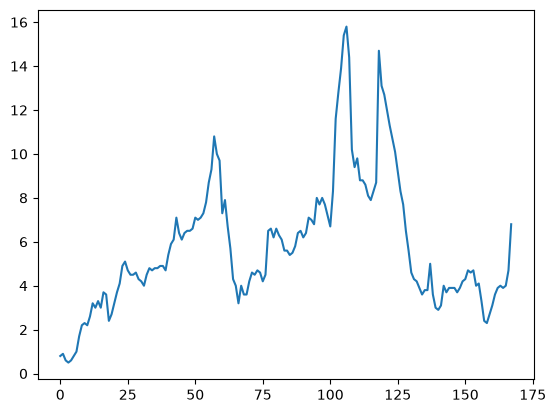

In [22]:
# Cell 22
site2.head(168).plot()
plt.show()

<div style="border-left:7px solid #2f80ed;background:rgba(47,128,237,.12);padding:10px 18px;margin:10px 0;border-radius:8px;line-height:1.5">
    How are the readings spread over the whole year? Cut the range into bins and count the hours in each; that picture is a <b>histogram</b>, and <code>.hist(bins=40)</code> draws it. Most hours bunch up between about 2 and 10, and a thin tail runs out to the right, as far as 62. That is why the mean, 8.13, sits above the median, 6.4.
</div>

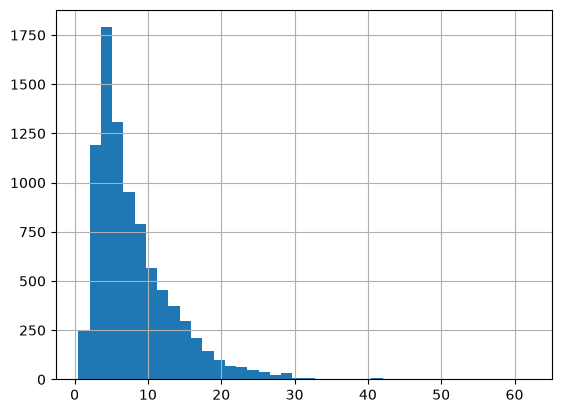

In [23]:
# Cell 23
site2.hist(bins=40)
plt.show()

<div style="border-left:7px solid #2f80ed;background:rgba(47,128,237,.12);padding:10px 18px;margin:10px 0;border-radius:8px;line-height:1.5">
    How do I compare the sites in a picture? Take the <code>means</code> from before, eight numbers with the site as the label, and add <code>.plot.bar()</code>. Each site becomes one bar. Sites 1008 and 0067 have fewer hours than the others, so their bars average a different stretch of the year. The bars run left to right in the order of the site IDs, so the first one is site 0002, at 8.13.
</div>

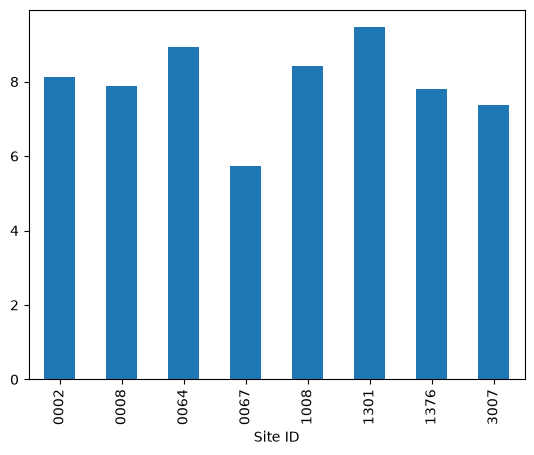

In [24]:
# Cell 24
means.plot.bar()
plt.show()

<div style="border-left:7px solid #2f80ed;background:rgba(47,128,237,.12);padding:10px 18px;margin:10px 0;border-radius:8px;line-height:1.5">
    <div style="font-weight:700;font-size:1.08em;margin-bottom:4px">
        🎯 The vocabulary, at a glance
    </div>
    <ul>
        <li>
            <b>Standard library:</b> <code>max</code>, <code>min</code>, <code>type</code>, <code>math.isnan</code> and the <code>statistics</code> module. Nothing to install.
        </li>
        <li>
            <b>NumPy arrays:</b> <code>np.array</code> turns a list into one. <code>mean</code>, <code>median</code>, <code>std</code>, <code>percentile</code>. <code>ddof=1</code> gives the sample standard deviation.
        </li>
        <li>
            <b>Missing values:</b> <code>np.nan</code> poisons a plain <code>mean</code>; <code>np.nanmean</code> skips it. pandas skips it by default. <code>np.isnan</code> finds the blanks, and <code>~</code> flips the answer to keep the rest.
        </li>
        <li>
            <b>Masks:</b> <code>pm25_array &gt; 35</code> gives True and False. <code>.sum()</code> counts them, and <code>pm25_array[mask]</code> selects them.
        </li>
        <li>
            <b>pandas:</b> <code>head</code>, <code>unique</code>, <code>describe</code>, <code>value_counts</code>, <code>groupby(...).mean()</code>.
        </li>
        <li>
            <b>Sanity checks:</b> row counts per site, units and parameter codes, and the minimum and maximum.
        </li>
        <li>
            <b>Timing:</b> <code>%timeit</code> runs a line many times and reports how long one run takes.
        </li>
        <li>
            <b>Plots:</b> <code>.plot()</code>, <code>.hist()</code>, <code>.plot.bar()</code>, then <code>plt.show()</code>.
        </li>
    </ul>
</div>